# Liana+ and Tensor Cell2Cell analysis
Perform Cell-Cell Communication inference using Liana+ and Tensor Cell2Cell

In [1]:
import pandas as pd
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt
import torch
import liana as li
import cell2cell as c2c
import scanpy as sc

/gpfs/data01/teleselab/agurha/miniconda3/envs/thc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/gpfs/data01/teleselab/agurha/miniconda3/envs/thc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/gpfs/data01/teleselab/agurha/miniconda3/envs/thc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/gpfs/data01/teleselab/agurha/miniconda3/envs/thc/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_mtx from `anndata` is deprecated. Import anndata.io.read_mtx instead.
  warnings.warn(msg, FutureWarning)
/gpfs/data01/teleselab/agurha/miniconda3/envs/

## Load Data and resources
Data has been converted from the Seurat object and so labels must be gene names must be loaded and assigned. 

Our dataset is mouse so we need find the orthologs for the human symbols.

In [2]:
adata = sc.read_h5ad("data.h5ad")

In [3]:
ot = []

with open("lst.txt", "r") as f:
    ot = f.readlines()
ot = [m.strip() for m in ot]

In [5]:
adr = adata.raw.to_adata()

In [6]:
adr.var_names = ot

In [7]:
import omnipath as op
import decoupler as dc
# mouse homologs of human genes
map_df = li.rs.get_hcop_orthologs(url='https://ftp.ebi.ac.uk/pub/databases/genenames/hcop/human_mouse_hcop_fifteen_column.txt.gz',
                                  columns=['human_symbol', 'mouse_symbol'],
                                   # NOTE: HCOP integrates multiple resource, so we can filter out mappings in at least 3 of them for confidence
                                   min_evidence=3
                                   )
# rename the columns to source and target, respectively for the original organism and the target organism
map_df = map_df.rename(columns={'human_symbol':'source', 'mouse_symbol':'target'})
# We will then translate
resource = li.rs.select_resource('consensus')
mouse = li.rs.translate_resource(resource,
                                 map_df=map_df,
                                 columns=['ligand', 'receptor'],
                                 replace=True,
                                 # Here, we will be harsher and only keep mappings that don't map to more than 1 mouse gene
                                 one_to_many=1
                                 )

/gpfs/data01/teleselab/agurha/miniconda3/envs/thc/lib/python3.10/site-packages/liana/resource/_orthology.py:199: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.


## QC plots
Filter out cell types which have low representation in multiple samples.

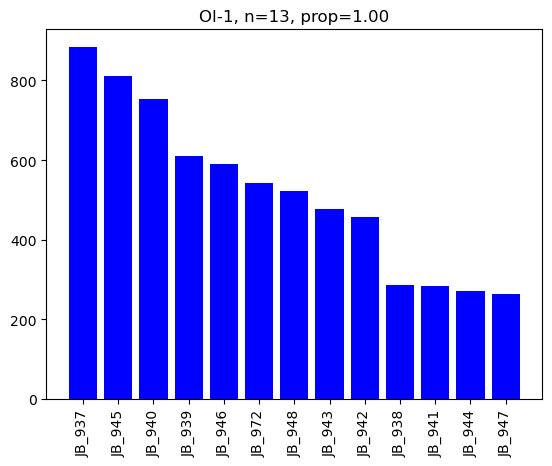

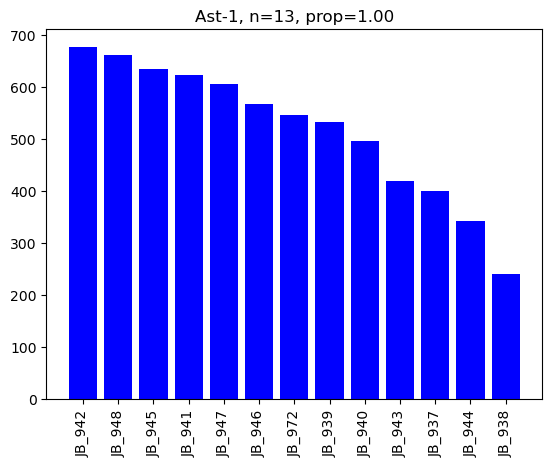

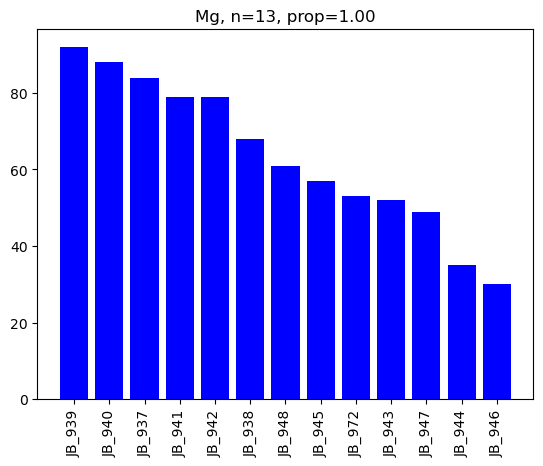

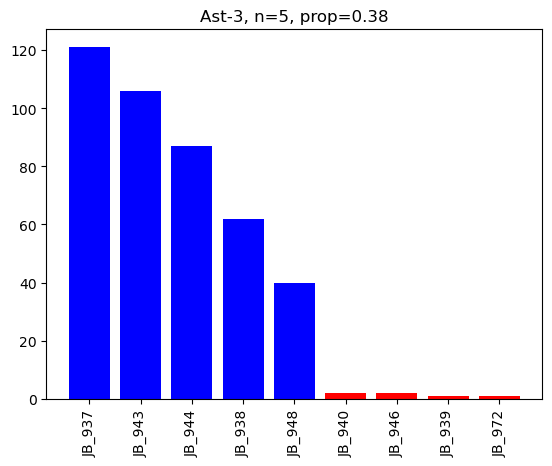

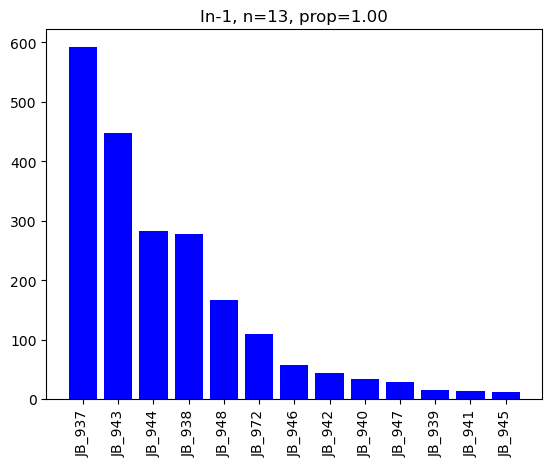

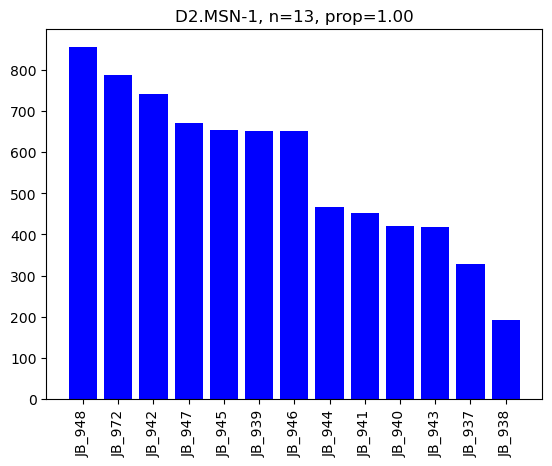

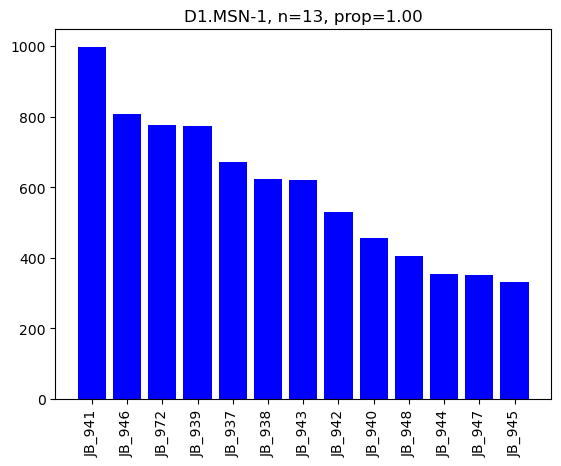

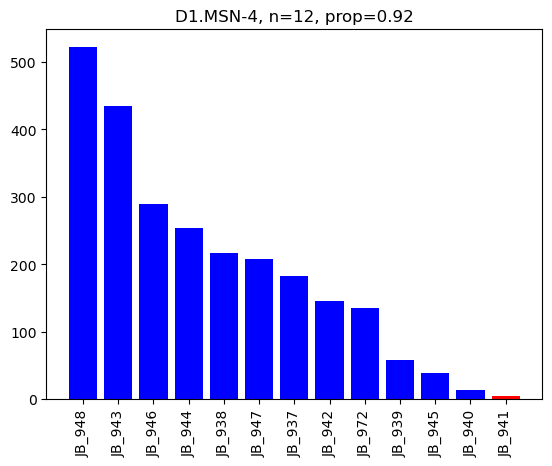

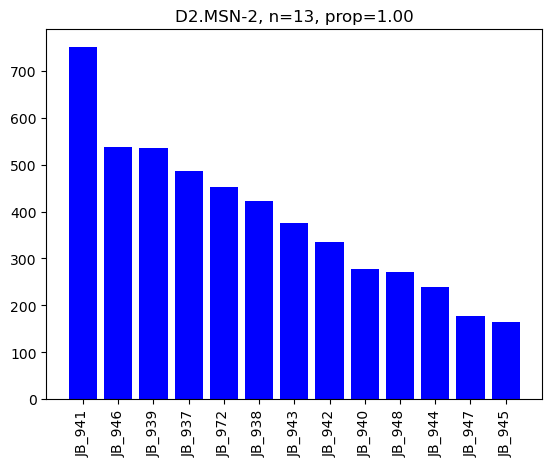

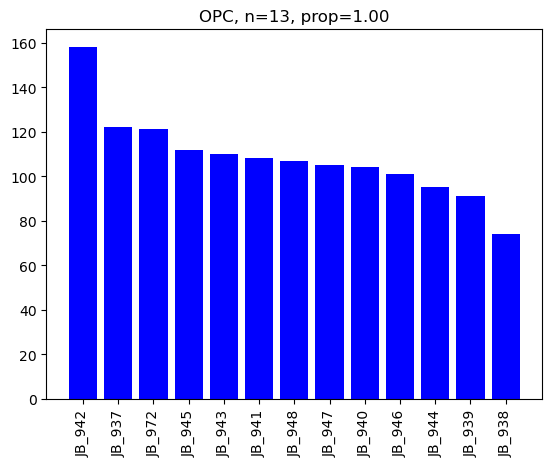

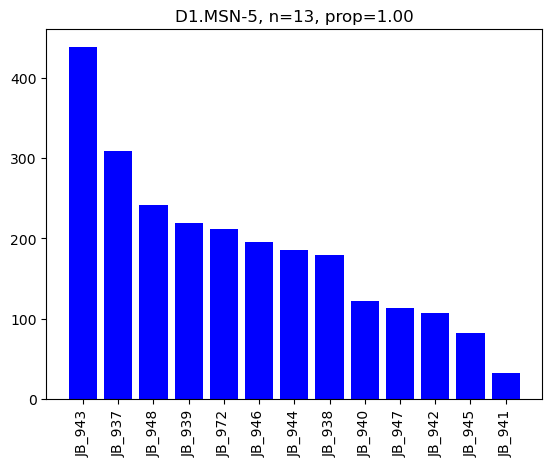

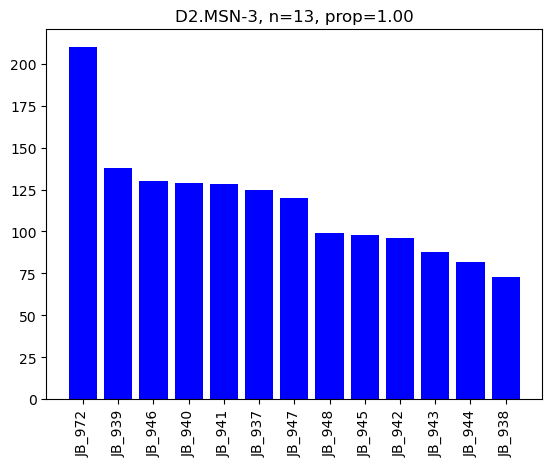

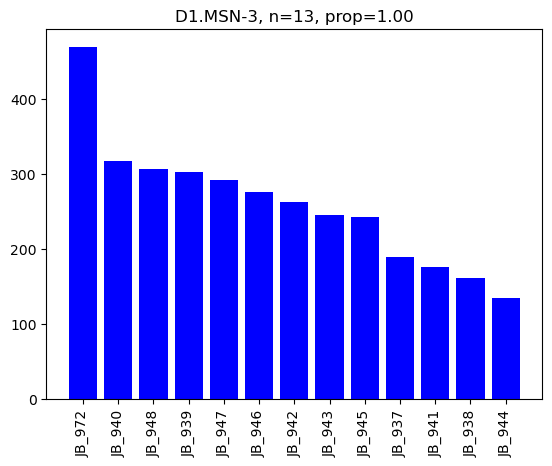

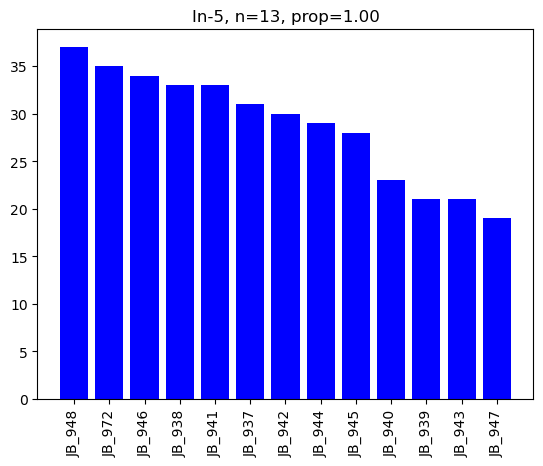

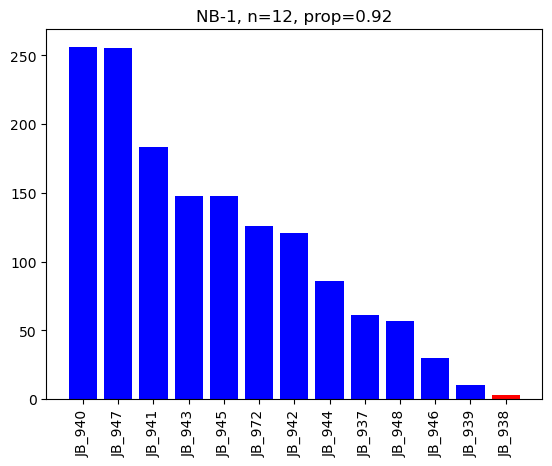

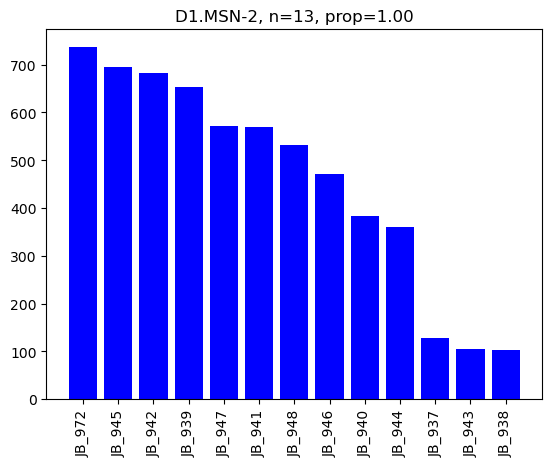

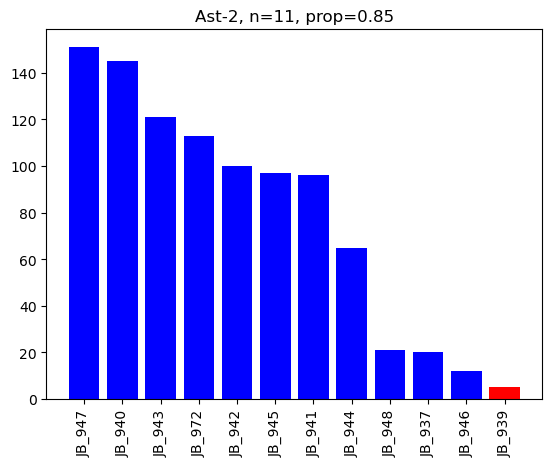

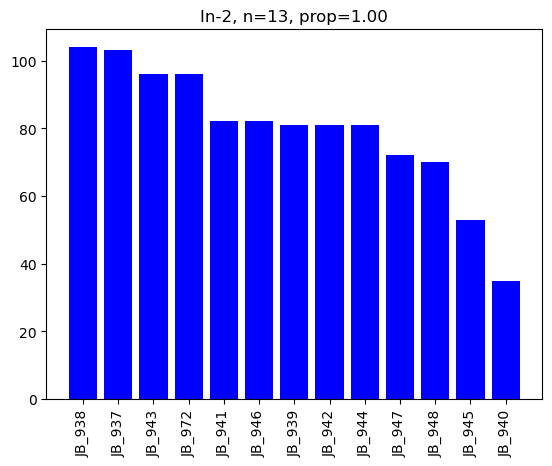

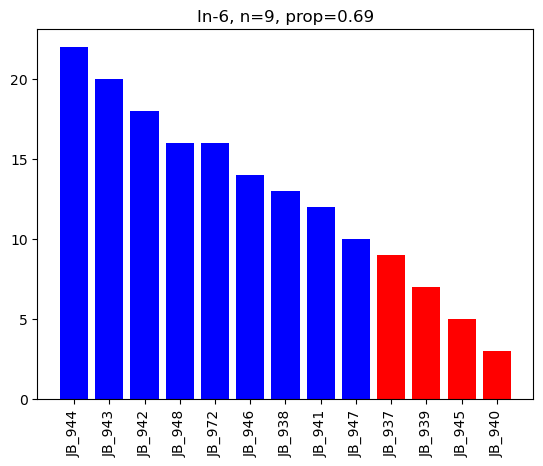

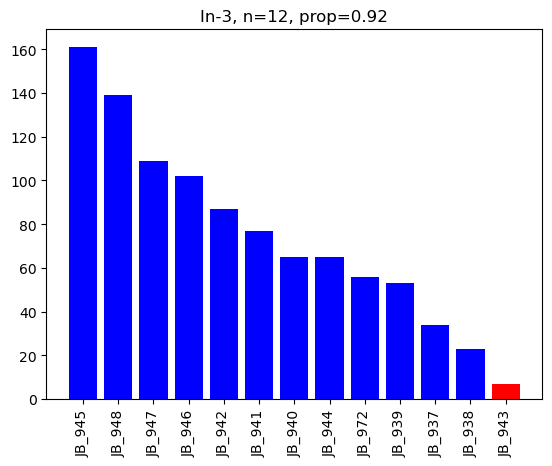

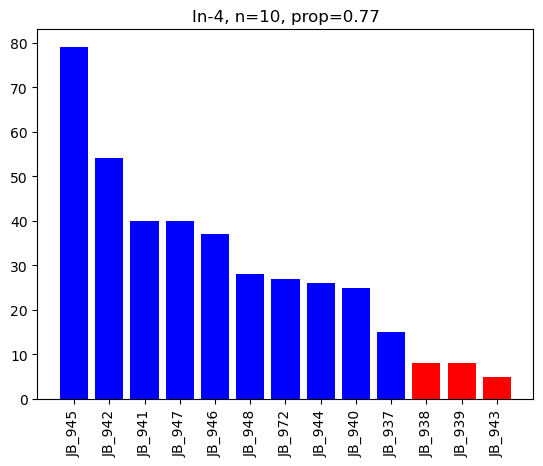

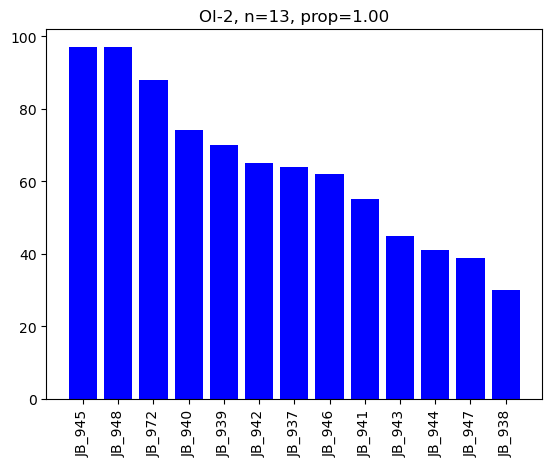

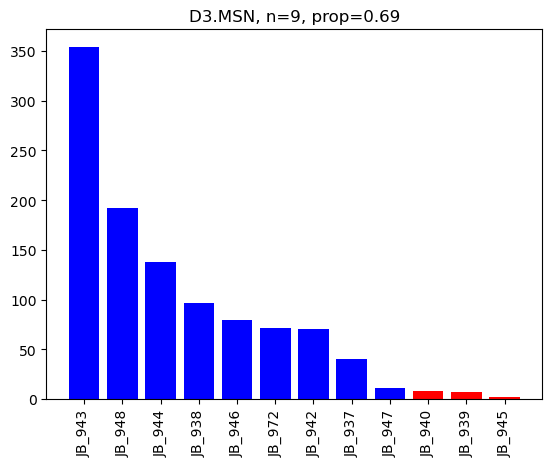

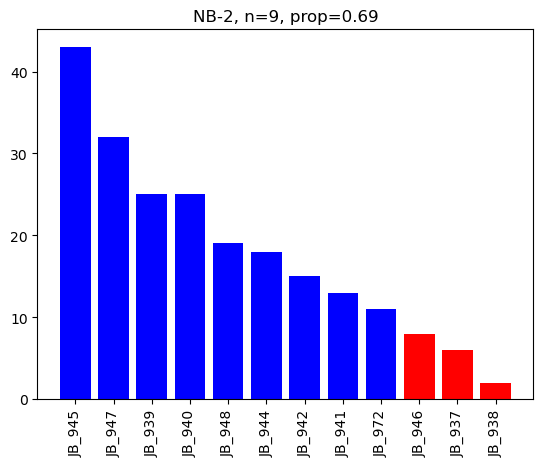

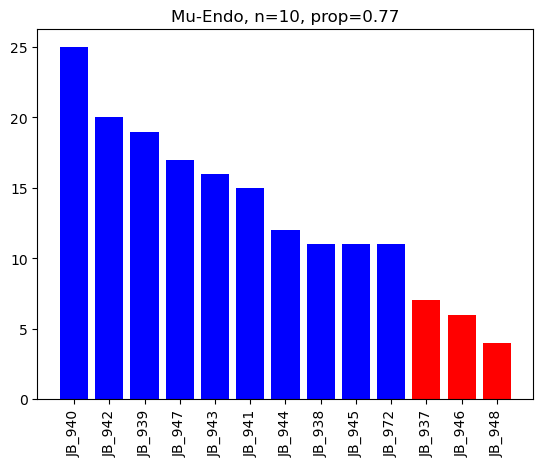

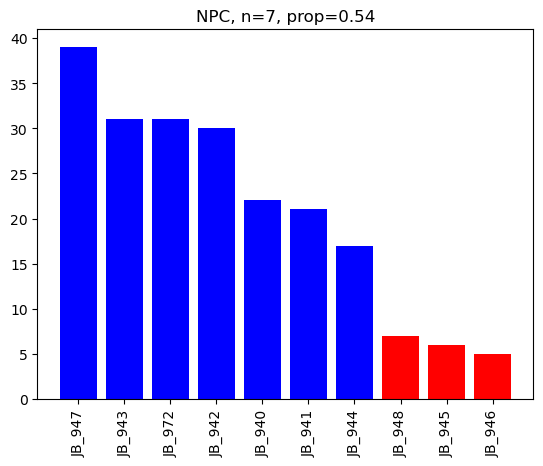

In [8]:
min_cells = 10
n_samples = len(adr.obs['orig.ident'].unique())
omit = []

for i in adr.obs["detailed.celltype"].unique():
    vc = adr[adr.obs["detailed.celltype"] == i].obs["orig.ident"].value_counts()
    colors = ['blue'] * len(vc)
    n_s = 0
    for iss, vals in enumerate(vc.values):
        if vals < min_cells:
            colors[iss] = 'red'
        else:
            n_s+=1
    if n_s/n_samples < 0.7:
        omit.append(i)
    plt.bar(vc.index, vc.values, color=colors)
    plt.title(f"{i}, n={n_s}, prop={(n_s/n_samples):.2f}")
    plt.xticks(rotation=90)
    plt.show()
    

In [9]:
omit = ['Ast-3', 'In-6', 'D3.MSN', 'NB-2', 'NPC']

In [10]:
filtered_ds = adr[~adr.obs["detailed.celltype"].isin(omit)]

## Perform Liana+ analysis and construct tensor
The magnitude_rank score is used. It must be inverted prior to tensor construction.

In [11]:
li.mt.rank_aggregate.by_sample(
    filtered_ds,
    groupby="detailed.celltype",
    resource=mouse,
    sample_key="orig.ident", # sample key by which we which to loop
    use_raw=False, 
    verbose=True, # use 'full' to show all verbose information
    n_perms=None, # exclude permutations for speed
    return_all_lrs=True, # return all LR values
    )

Converting `orig.ident` to categorical!
/gpfs/data01/teleselab/agurha/miniconda3/envs/thc/lib/python3.10/site-packages/liana/method/sc/_Method.py:126: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
Now running: JB_937:   0%|                               | 0/13 [00:00<?, ?it/s]/gpfs/data01/teleselab/agurha/miniconda3/envs/thc/lib/python3.10/site-packages/anndata/_core/anndata.py:381: FutureWarning: The dtype argument is deprecated and will be removed in late 2024.
/gpfs/data01/teleselab/agurha/miniconda3/envs/thc/lib/python3.10/site-packages/liana/method/_pipe_utils/_pre.py:271: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
/gpfs/data01/teleselab/agurha/miniconda3/envs/thc/lib/python3.10/site-packages/liana/method/_pipe_utils/_pre.py:153: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to r

In [13]:
tensor = li.multi.to_tensor_c2c(
                                    filtered_ds,
                                    sample_key="orig.ident",
                                    score_key='magnitude_rank', # can be any score from liana
                                    how='outer_cells', # how to join the samples
                                    non_negative = True, # set negative values to 0
                                    inverse_fun=lambda x: 1 - x,
                                    
                                )

100%|██████████████████████████████████████████| 13/13 [33:34<00:00, 154.99s/it]


In [14]:
context_dict = filtered_ds.obs[["orig.ident", "Treatment"]].drop_duplicates()
context_dict = dict(zip(context_dict["orig.ident"], context_dict["Treatment"]))
context_dict = defaultdict(lambda: 'Unknown', context_dict)

tensor_meta = c2c.tensor.generate_tensor_metadata(interaction_tensor=tensor,
                                                  metadata_dicts=[context_dict, None, None, None],
                                                  fill_with_order_elements=True
                                                  )

## Perform Tensor Cell2Cell factorization analysis
Run the tensor cell2cell pipeline. Ensure that the correct version of pytorch is installed for your cuda version to allow for gpu based operations. To test run the following and ensure True is returned:
```python
import torch
print(torch.cuda.is_available())
```

In [15]:
import tensorly as tl
tl.set_backend("pytorch")

In [ ]:
tensor = c2c.analysis.run_tensor_cell2cell_pipeline(tensor,
                                                    tensor_meta,
                                                    copy_tensor=True, # Whether to output a new tensor or modifying the original
                                                    rank=None, # Number of factors to perform the factorization. If None, it is automatically determined by an elbow analysis. Here, it was precomuputed.
                                                    tf_optimization='regular', # To define how robust we want the analysis to be. 
                                                    random_state=0, # Random seed for reproducibility
                                                    device="cuda", # Device to use. If using GPU and PyTorch, use 'cuda'. For CPU use 'cpu'
                                                    elbow_metric='error', # Metric to use in the elbow analysis.
                                                    smooth_elbow=False, # Whether smoothing the metric of the elbow analysis.
                                                    upper_rank=20, # Max number of factors to try in the elbow analysis
                                                    tf_init='random', # Initialization method of the tensor factorization
                                                    tf_svd='numpy_svd', # Type of SVD to use if the initialization is 'svd'
                                                    cmaps=None, # Color palettes to use in color each of the dimensions. Must be a list of palettes.
                                                    sample_col='Element', # Columns containing the elements in the tensor metadata
                                                    group_col='Category', # Columns containing the major groups in the tensor metadata
                                                    output_fig=False, # Whether to output the figures. If False, figures won't be saved a files if a folder was passed in output_folder.
                                                    )

/gpfs/data01/teleselab/agurha/miniconda3/envs/thc/lib/python3.10/site-packages/tensorly/backend/pytorch_backend.py:39: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).


Running Elbow Analysis


 20%|████████▊                                   | 4/20 [01:27<07:05, 26.61s/it]

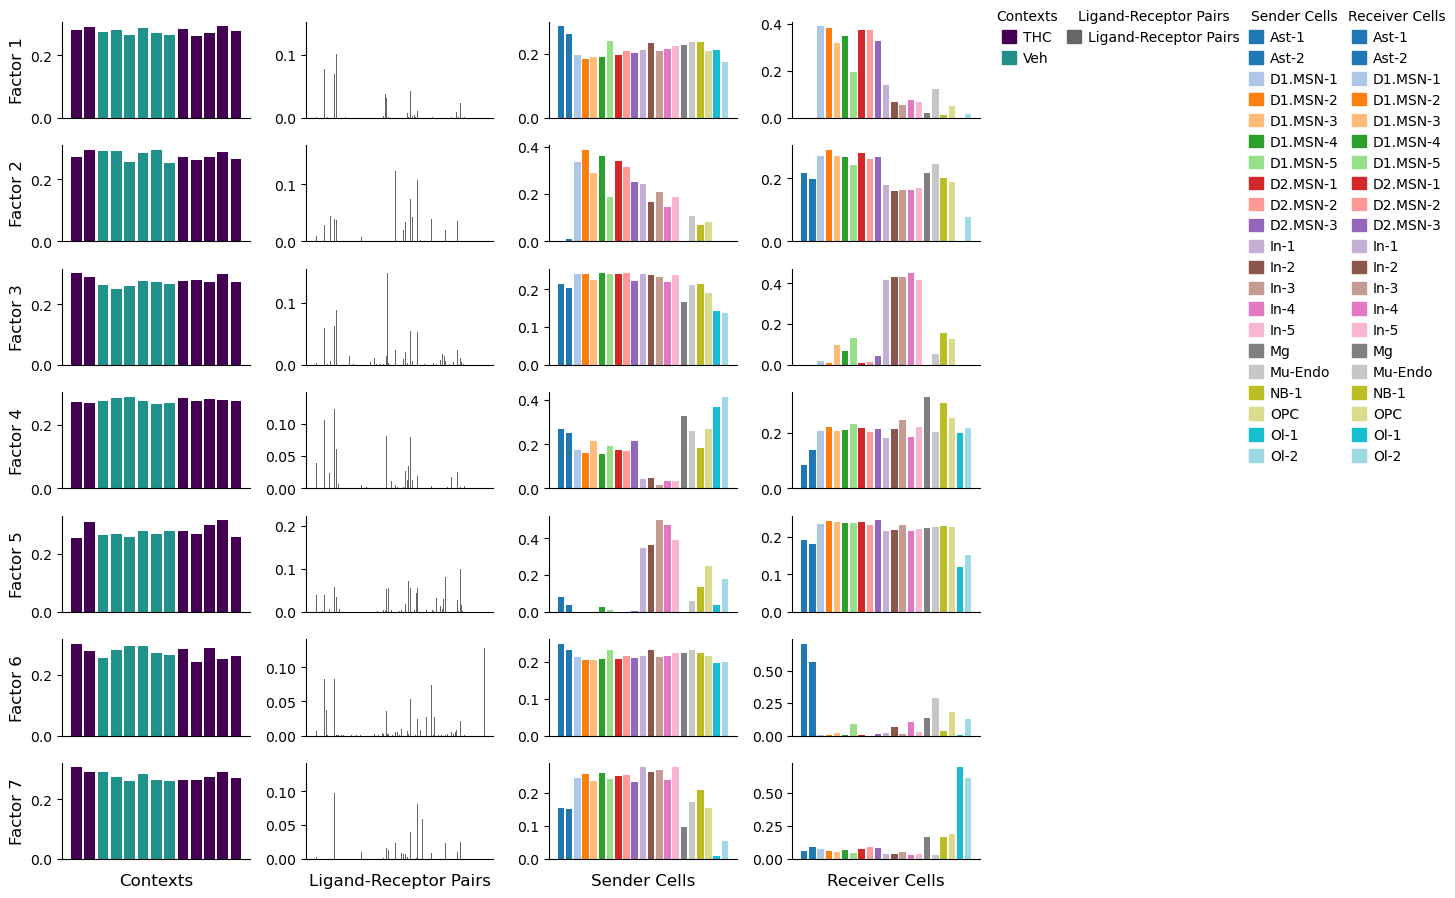

In [134]:
factors, axes = c2c.plotting.tensor_factors_plot(interaction_tensor=tensor,
                                                 metadata = tensor_meta, # This is the metadata for each dimension
                                                 sample_col='Element',
                                                 group_col='Category',
                                                 meta_cmaps = ['viridis', 'Dark2_r', 'tab20', 'tab20'],
                                                 fontsize=10, # Font size of the figures generated
                                                 filename="figures/total.pdf"
                                                 )

/gpfs/data01/teleselab/agurha/miniconda3/envs/thc/lib/python3.10/site-packages/cell2cell/plotting/factor_plot.py:146: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

/gpfs/data01/teleselab/agurha/miniconda3/envs/thc/lib/python3.10/site-packages/cell2cell/plotting/factor_plot.py:197: UserWarning: FixedFormatter should only be used together with FixedLocator
/gpfs/data01/teleselab/agurha/miniconda3/envs/thc/lib/python3.10/site-packages/cell2cell/plotting/factor_plot.py:146: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

/gpfs/data01/teleselab/agurha/miniconda3/envs/thc/lib/python3.10/site-packages/cell2cell/plotting/factor_plot.py:197: UserWarning: FixedFormatter should only be used together with FixedLocator
/gpfs/data01

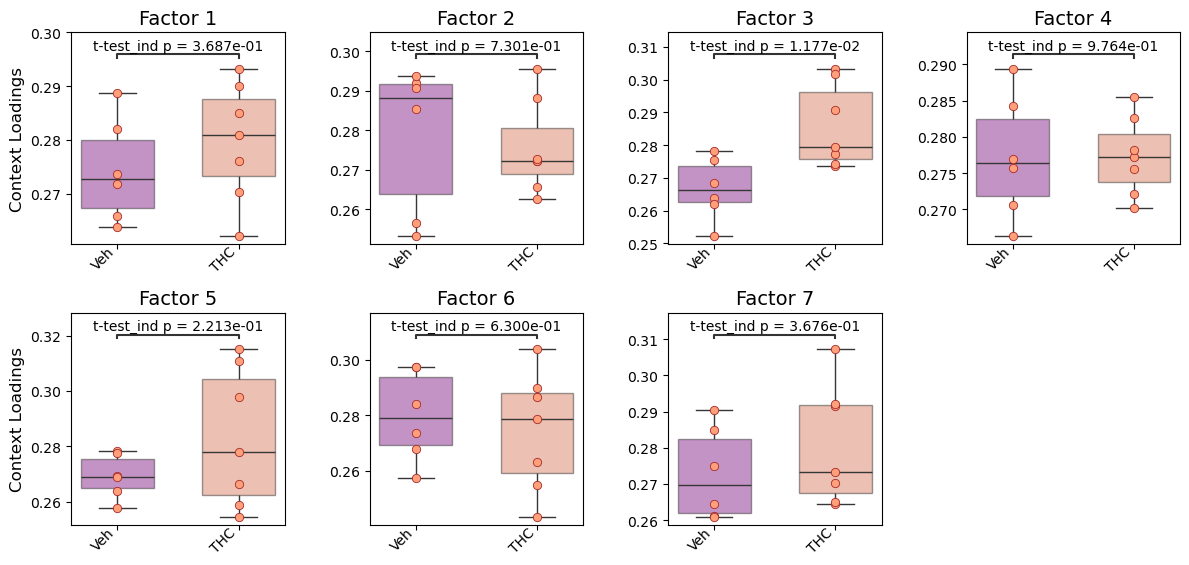

In [20]:
factors = c2c.io.load_tensor_factors("factor.xlsx")
factors = tensor.factors

_ = c2c.plotting.context_boxplot(context_loadings=factors["Contexts"],
                                 metadict=context_dict,
                                 nrows=2,
                                 figsize=(12, 6),
                                 statistical_test='t-test_ind',
                                 pval_correction='fdr_bh',
                                 cmap='plasma',
                                 verbose=False,
                                 filename="figures/boxplot.pdf",
                                 text_format="full"
                                )

(<Figure size 800x800 with 1 Axes>, <Axes: title={'center': 'Factor 3'}>)

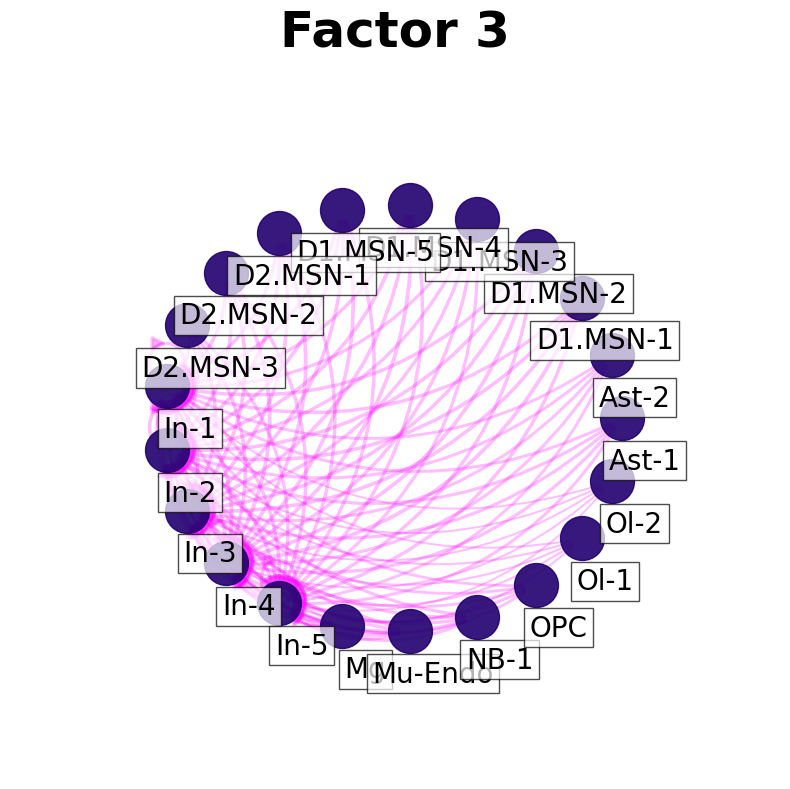

In [25]:
c2c.plotting.ccc_networks_plot(factors,
                               included_factors=['Factor 3'],
                               network_layout='circular',
                               ccc_threshold=0.05, # Only important communication
                               nrows=1,
                               panel_size=(8, 8), # This changes the size of each figure panel.
                               filename="figures/circleplot.pdf"
                              )

In [26]:
loading_product = c2c.analysis.tensor_downstream.get_joint_loadings(tensor.factors,
                                                                    dim1='Sender Cells',
                                                                    dim2='Receiver Cells',
                                                                    factor="Factor 3",
                                                                   )

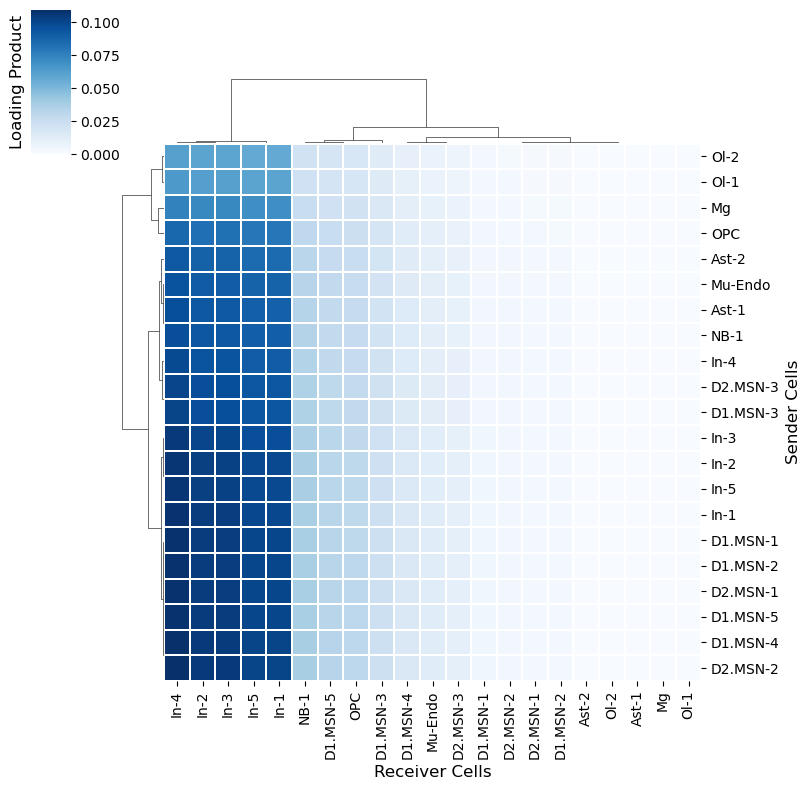

In [27]:
lprod_cm = c2c.plotting.loading_clustermap(loading_product.T, # Remove .T to transpose the axes
                                           use_zscore=False, # Whether standardizing the loadings across factors
                                           figsize=(8, 8),
                                           cbar_label='Loading Product',
                                           filename="figures/heatmap.pdf"
                                          )